## D4 · t-tests

One-sample, paired and independent t-tests with scipy, confidence intervals, QQ plots and reporting.

In [1161]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Plot defaults: wide 16:9 figures, sharp ("retina") output and slightly smaller text
%config InlineBackend.figure_format = "retina"
plt.rcParams.update({
    "figure.figsize": (6.4, 3.6),
    "figure.dpi": 100,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

# Same data as sns.load_dataset('penguins'), saved locally so it works offline
df_penguins = pd.read_csv("data/penguins.csv")

# Two blood-pressure experiments (course data)
df_bp1 = pd.read_csv("data/bp_experiment1.csv")      # long format: id, gender, group, bp
df_bp2 = pd.read_csv("data/bp_experiment2.csv")      # wide format: bp_day1, bp_day30 for each person
col_test = df_bp1.loc[df_bp1["group"] == "test", "bp"]
col_control = df_bp1.loc[df_bp1["group"] == "control", "bp"]
col_diffs = df_bp2["bp_day30"] - df_bp2["bp_day1"]

### Choosing a test

#### Choosing a t-test

**D4.01**

`one sample vs paired vs independent`

Asking how the data were collected allows us to choose the right t-test: one group against a value, the same people twice, or two different groups. It is useful because the wrong test gives a wrong answer. Alternatively, a non-parametric test (such as Mann–Whitney) is the choice when the data are clearly not normal.

**Context.** The data are from two blood-pressure experiments (in mmHg). In experiment 1, one group received a treatment (test) and one did not (control); each person was measured once. In experiment 2, the same people were measured on day 1 and on day 30.

- **One sample**: one group compared with a known value.
- **Paired**: the *same* subjects measured twice (before/after).
- **Independent (Welch)**: two *different* groups.
Experiment 1 has two different groups of people, so it needs an independent test:

In [1162]:
# display the example data
df_bp1.groupby("group")["bp"].agg(["count", "mean"]).round(1)

,count,mean
group,,
control,30,150.4
test,30,147.8


Experiment 2 has the same people measured twice, so it needs a paired test:

In [1163]:
# display example data
df_bp2.head(3)

,id,gender,bp_day1,bp_day30
0,1,f,153.0,150.0
1,2,f,143.0,139.0
2,3,m,151.0,156.0


*See also:* One-sample t-tests (D4) · Paired t-tests (D4) · Independent (Welch) t-tests (D4) · Reading the t-test output (D4)

### Running a test

#### One-sample t-tests

**D4.02**

`stats.ttest_1samp(x, popmean=mu0, alternative=side)`

The `stats.ttest_1samp()` function allows us to test whether the mean of one group differs from a given value. It is useful for comparing a sample with a target or known standard. Alternatively, a confidence interval for the mean gives the same information.

**Context.** The data are from two blood-pressure experiments (in mmHg). In experiment 1, one group received a treatment (test) and one did not (control); each person was measured once. In experiment 2, the same people were measured on day 1 and on day 30.

The question: does the mean blood pressure of the test group differ from the target value of 140 mmHg?
Assumptions: the observations are independent, and the data are approximately normal (or the sample is large). A QQ plot checks the second assumption (see the linked examples).

In [1164]:
# display the example data
print(f"test group: n = {len(col_test)}, mean = {col_test.mean():.1f} mmHg, sd = {col_test.std():.1f} mmHg")

test group: n = 30, mean = 147.8 mmHg, sd = 11.3 mmHg


In [1165]:
mu0 = 140
res = stats.ttest_1samp(col_test, popmean=mu0)
print(f"t({res.df}) = {res.statistic:.2f}, p = {res.pvalue:.4f}")

t(29) = 3.78, p = 0.0007


In [1166]:
print(f"The test group mean ({col_test.mean():.1f} mmHg) differs from {mu0} mmHg by {col_test.mean() - mu0:+.1f} mmHg (p = {res.pvalue:.4f}). "
      + ("This is below 0.05, so H₀ (mean = 140 mmHg) is rejected." if res.pvalue < 0.05 else "This is not below 0.05, so H₀ (mean = 140 mmHg) is not rejected."))

The test group mean (147.8 mmHg) differs from 140 mmHg by +7.8 mmHg (p = 0.0007). This is below 0.05, so H₀ (mean = 140 mmHg) is rejected.


*See also:* Choosing a t-test (D4) · A paired test as a one-sample test (D4) · QQ plots (D4) · Testing for normality (D4)

#### Paired t-tests

**D4.03**

`stats.ttest_rel(after, before)`

The `stats.ttest_rel()` function allows us to test whether the mean difference between two measurements on the same subjects is zero. It is useful for before/after designs. Alternatively, calculate the differences and run a one-sample test on them.

**Context.** The data are from two blood-pressure experiments (in mmHg). In experiment 1, one group received a treatment (test) and one did not (control); each person was measured once. In experiment 2, the same people were measured on day 1 and on day 30.

Assumptions: the two measurements come from the same subjects, and the *differences* are approximately normal. The QQ plot of the differences checks this.

In [1167]:
# display the example data
df_bp2.head(3)

,id,gender,bp_day1,bp_day30
0,1,f,153.0,150.0
1,2,f,143.0,139.0
2,3,m,151.0,156.0


In [1168]:
res = stats.ttest_rel(df_bp2["bp_day30"], df_bp2["bp_day1"])
print(f"mean change = {col_diffs.mean():.2f} mmHg")

mean change = -4.43 mmHg


In [1169]:
print(f"t({res.df}) = {res.statistic:.2f}, p = {res.pvalue:.4f}")

t(29) = -4.64, p = 0.0001


In [1170]:
print(f"Blood pressure changed by {col_diffs.mean():+.1f} mmHg on average between day 1 and day 30 (p = {res.pvalue:.4f}). "
      + ("This is below 0.05, so there is evidence of a change." if res.pvalue < 0.05 else "This is not below 0.05, so there is no evidence of a change at the 5% level."))

Blood pressure changed by -4.4 mmHg on average between day 1 and day 30 (p = 0.0001). This is below 0.05, so there is evidence of a change.


*See also:* A paired test as a one-sample test (D4) · Independent (Welch) t-tests (D4) · QQ plots (D4)

#### A paired test as a one-sample test

**D4.04**

`stats.ttest_1samp(after - before, 0)`

Testing the differences against 0 with `ttest_1samp` allows us to reproduce a paired t-test exactly. It is useful for understanding what "paired" means: it is a one-sample test on the changes. Alternatively, use `ttest_rel` directly.

**Context.** The data are from two blood-pressure experiments (in mmHg). In experiment 1, one group received a treatment (test) and one did not (control); each person was measured once. In experiment 2, the same people were measured on day 1 and on day 30.

Assumptions: the differences are independent and approximately normal, as for the paired t-test.

In [1171]:
col_d = df_bp2["bp_day30"] - df_bp2["bp_day1"]       # the change for each person
col_d.head().tolist()

[-3.0, -4.0, 5.0, -8.0, -4.0]

In [1172]:
res_one = stats.ttest_1samp(col_d, 0)
res_pair = stats.ttest_rel(df_bp2["bp_day30"], df_bp2["bp_day1"])
print(f"one-sample on differences: t = {res_one.statistic:.4f}, p = {res_one.pvalue:.4f}")

one-sample on differences: t = -4.6367, p = 0.0001


In [1173]:
print(f"paired test              : t = {res_pair.statistic:.4f}, p = {res_pair.pvalue:.4f}")

paired test              : t = -4.6367, p = 0.0001


In [1174]:
'The two tests give ' + ('identical' if np.isclose(res_one.pvalue, res_pair.pvalue) else 'different') + f' results (t = {res_one.statistic:.4f} and {res_pair.statistic:.4f}), so a paired test is a one-sample test on the differences.'

'The two tests give identical results (t = -4.6367 and -4.6367), so a paired test is a one-sample test on the differences.'

*See also:* Paired t-tests (D4) · One-sample t-tests (D4) · QQ plots (D4)

#### Independent (Welch) t-tests

**D4.05**

`stats.ttest_ind(a, b, equal_var=False)`

The `stats.ttest_ind(..., equal_var=False)` function allows us to compare the means of two different groups without assuming equal variances. It is useful for control vs treatment experiments. Alternatively, `equal_var=True` gives the classic Student test.

**Context.** The data are from two blood-pressure experiments (in mmHg). In experiment 1, one group received a treatment (test) and one did not (control); each person was measured once. In experiment 2, the same people were measured on day 1 and on day 30.

Assumptions: the observations are independent (different people in each group) and each group is approximately normal, or large. Welch's test does not need equal variances; Student's does.

In [1175]:
# display the example data
df_bp1.groupby("group")["bp"].agg(["count", "mean", "std"]).round(1)

,count,mean,std
group,,,
control,30,150.4,11.7
test,30,147.8,11.3


In [1176]:
res = stats.ttest_ind(col_test, col_control, equal_var=False)
print(f"t({res.df:.1f}) = {res.statistic:.2f}, p = {res.pvalue:.4f}")

t(57.9) = -0.88, p = 0.3799


In [1177]:
diff = col_test.mean() - col_control.mean()
print(f"The test group mean is {abs(diff):.1f} mmHg {'lower' if diff < 0 else 'higher'} than the control group mean (p = {res.pvalue:.4f}). "
      + ("This is below 0.05, so there is evidence of a difference." if res.pvalue < 0.05 else "This is not below 0.05, so there is no evidence at the 5% level of a difference between the groups."))

The test group mean is 2.6 mmHg lower than the control group mean (p = 0.3799). This is not below 0.05, so there is no evidence at the 5% level of a difference between the groups.


*See also:* Student or Welch (D4) · One- or two-sided tests (D4) · Comparing groups with a box plot (D4) · QQ plots (D4) · Testing for equal variances (D4)

#### Student or Welch

**D4.06**

`equal_var=True / False`

The `equal_var` argument allows us to choose between Student's t-test (equal variances assumed) and Welch's (not assumed). It is useful when the two groups may have different spreads, because Welch's test remains valid and is rarely much worse. Alternatively, test the equal-variance assumption first with Levene's test.

**Context.** The data are from two blood-pressure experiments (in mmHg). In experiment 1, one group received a treatment (test) and one did not (control); each person was measured once. In experiment 2, the same people were measured on day 1 and on day 30.

In [1178]:
p_student = stats.ttest_ind(col_test, col_control, equal_var=True).pvalue
p_welch = stats.ttest_ind(col_test, col_control, equal_var=False).pvalue
print(f"Student (equal_var=True) : p = {p_student:.4f}")

Student (equal_var=True) : p = 0.3799


In [1179]:
print(f"Welch   (equal_var=False): p = {p_welch:.4f}")

Welch   (equal_var=False): p = 0.3799


In [1180]:
print(f"The two p-values differ by {abs(p_student - p_welch):.4f}. They are close when the two groups have similar sizes and spreads (standard deviations {col_test.std():.1f} and {col_control.std():.1f} mmHg here).")

The two p-values differ by 0.0000. They are close when the two groups have similar sizes and spreads (standard deviations 11.3 and 11.7 mmHg here).


*See also:* Independent (Welch) t-tests (D4) · Testing for equal variances (D4) · Comparing groups with a box plot (D4)

### The alternative hypothesis

#### One- or two-sided tests

**D4.07**

`alternative="two-sided" / "less" / "greater"`

The `alternative=` argument allows us to run a one-sided test (`"less"` or `"greater"`) instead of the two-sided default. It is useful when H₁ names one direction before the data are collected, such as a treatment that matters only if it **lowers** blood pressure. Alternatively, keep the two-sided default whenever an effect in either direction would matter.

**Context.** The data are from two blood-pressure experiments (in mmHg). In experiment 1, one group received a treatment (test) and one did not (control); each person was measured once. In experiment 2, the same people were measured on day 1 and on day 30.

Note: the direction of a one-sided test comes from the question and is fixed before the data are examined. Choosing it afterwards, to match the direction the data went, doubles the false-positive rate. The assumptions are those of the t-test (independent observations; approximately normal data or a large sample).

Here H₁, stated before the experiment, is "the treatment lowers blood pressure", so the test group (first) should have the **smaller** mean and the one-sided test is `alternative="less"`. All three settings are printed to show how they differ, but only the one chosen in advance is reported.
Watch out: **Order matters**: `"less"` tests whether the **first** sample has a smaller mean than the second.

In [1181]:
# display the example data
print(f"means: test {col_test.mean():.1f} mmHg, control {col_control.mean():.1f} mmHg")

means: test 147.8 mmHg, control 150.4 mmHg


In [1182]:
p_alt = {}
for alt in ["two-sided", "less", "greater"]:
    p_alt[alt] = stats.ttest_ind(col_test, col_control, equal_var=False, alternative=alt).pvalue
    print(f"{alt:10s} p = {p_alt[alt]:.4f}")

two-sided  p = 0.3799
less       p = 0.1899
greater    p = 0.8101


In [1183]:
p_less = p_alt["less"]
print(f"The pre-stated H₁ (treatment lowers blood pressure) is tested by \"less\": p = {p_less:.4f}, "
      + ("below 0.05, so there is evidence that the treatment lowers blood pressure. " if p_less < 0.05 else "not below 0.05, so there is no evidence at the 5% level that the treatment lowers blood pressure. ")
      + f"The \"greater\" p-value ({p_alt['greater']:.4f}) answers a question that was not asked and cannot be substituted after seeing the data; if either direction had mattered, the two-sided p = {p_alt['two-sided']:.4f} would be reported.")

The pre-stated H₁ (treatment lowers blood pressure) is tested by "less": p = 0.1899, not below 0.05, so there is no evidence at the 5% level that the treatment lowers blood pressure. The "greater" p-value (0.8101) answers a question that was not asked and cannot be substituted after seeing the data; if either direction had mattered, the two-sided p = 0.3799 would be reported.


*See also:* Independent (Welch) t-tests (D4) · One-tailed p-values (D3) · Deciding whether to reject H0 (D3) · Deciding the test before seeing the result (D6)

### Reading the output

#### Reading the t-test output

**D4.08**

`result.statistic, result.pvalue, result.df`

The attributes `.statistic`, `.pvalue` and `.df` of a test result allow us to pull out single numbers for a report. They are useful for writing `t(df) = …, p = …`. Alternatively, print the whole result object.

**Context.** The data are from two blood-pressure experiments (in mmHg). In experiment 1, one group received a treatment (test) and one did not (control); each person was measured once. In experiment 2, the same people were measured on day 1 and on day 30.

In [1184]:
res = stats.ttest_ind(col_test, col_control, equal_var=False)
res                                  # the whole result

TtestResult(statistic=np.float64(-0.8849171829996173), pvalue=np.float64(0.3798607047410204), df=np.float64(57.91302237780863))

In [1185]:
print(f"t  = {res.statistic:.3f}")

t  = -0.885


In [1186]:
print(f"p  = {res.pvalue:.4f}")

p  = 0.3799


In [1187]:
print(f"df = {res.df:.1f}")

df = 57.9


*See also:* Reporting a t-test (D4) · Confidence intervals (D4) · One- or two-sided tests (D4)

#### Confidence intervals

**D4.09**

`result.confidence_interval(confidence_level=level)`

The `result.confidence_interval()` method allows us to get a range of plausible values for the difference in means. It is useful because it shows the size and precision of an effect, not only whether it is "significant". Alternatively, build the interval from the standard error and `stats.t.ppf`.

**Context.** The data are from two blood-pressure experiments (in mmHg). In experiment 1, one group received a treatment (test) and one did not (control); each person was measured once. In experiment 2, the same people were measured on day 1 and on day 30.

Assumptions: the interval is valid under the assumptions of the test that produced it (independent observations; approximately normal data or a large sample).
One-sided tests give an interval that extends to ±infinity on one side.

In [1188]:
res = stats.ttest_ind(col_test, col_control, equal_var=False)
ci = res.confidence_interval(confidence_level=0.95)
print(f"95% CI for the difference in means: {ci.low:.1f} to {ci.high:.1f}")

95% CI for the difference in means: -8.6 to 3.3


*See also:* Critical t values (D4) · Reporting a t-test (D4) · Reading the t-test output (D4)

#### Critical t values

**D4.10**

`stats.t.ppf(q, df)`

***(non-examinable)***

The critical value `stats.t.ppf(0.975, df)` allows us to see what multiplies the standard error to make a 95% interval. It is useful for understanding confidence intervals. Alternatively, `result.confidence_interval()` does this automatically.

**Context.** The data are from two blood-pressure experiments (in mmHg). In experiment 1, one group received a treatment (test) and one did not (control); each person was measured once. In experiment 2, the same people were measured on day 1 and on day 30.

Assumption: the critical value of the t distribution applies when the data are drawn from an approximately normal population (or the sample is large).

In [1189]:
for df_ in (5, 29, 1000):
    print(f"df = {df_:4d}: critical t = {stats.t.ppf(0.975, df=df_):.3f}")
print(f"normal       : {round(stats.norm.ppf(0.975), 3)}")

df =    5: critical t = 2.571
df =   29: critical t = 2.045
df = 1000: critical t = 1.962
normal       : 1.96


*See also:* Confidence intervals (D4) · Percentiles with `ppf` (D2) · Reading the t-test output (D4)

#### The t statistic by hand

**D4.11**

`(x.mean() - mu0) / (x.std(ddof=1) / np.sqrt(len(x)))`

***(non-examinable)***

Calculating `(mean − μ₀) / (sd / √n)` ourselves allows us to see what the t statistic measures: how many standard errors the mean is from the target.

**Context.** The data are from two blood-pressure experiments (in mmHg). In experiment 1, one group received a treatment (test) and one did not (control); each person was measured once. In experiment 2, the same people were measured on day 1 and on day 30.

Assumption: the statistic follows a t distribution only if the data are approximately normal or the sample is large. The calculation itself holds for any data.

In [1190]:
mu0 = 140
t_manual = (col_test.mean() - mu0) / (col_test.std(ddof=1) / np.sqrt(len(col_test)))
t_scipy = stats.ttest_1samp(col_test, mu0).statistic
print(f"by hand = {t_manual:.4f}")

by hand = 3.7808


In [1191]:
print(f"scipy   = {t_scipy:.4f}")

scipy   = 3.7808


In [1192]:
f'The mean is {t_manual:.2f} standard errors from {mu0} mmHg, and the hand calculation ' + ('matches' if np.isclose(t_manual, t_scipy) else 'does not match') + ' the value from scipy.'

'The mean is 3.78 standard errors from 140 mmHg, and the hand calculation matches the value from scipy.'

*See also:* Choosing the standard deviation formula with `ddof` (A4) · One-sample t-tests (D4) · Reading the t-test output (D4)

### Checking assumptions

#### Comparing groups with a box plot

**D4.12**

`sns.boxplot(data=df, x='group', y='bp')`

If we have measurements for two groups, then box plots side by side show differences, spread and outliers before we test. It is useful as a check that a test is sensible. Alternatively, `sns.histplot(hue=...)` shows the full distributions.

**Context.** The data are from two blood-pressure experiments (in mmHg). In experiment 1, one group received a treatment (test) and one did not (control); each person was measured once. In experiment 2, the same people were measured on day 1 and on day 30.

In [1193]:
# display the example data
df_bp1.head()

,id,gender,group,bp
0,1,f,test,137.0
1,2,f,control,160.0
2,3,m,control,148.0
3,4,f,control,143.0
4,5,m,test,158.0


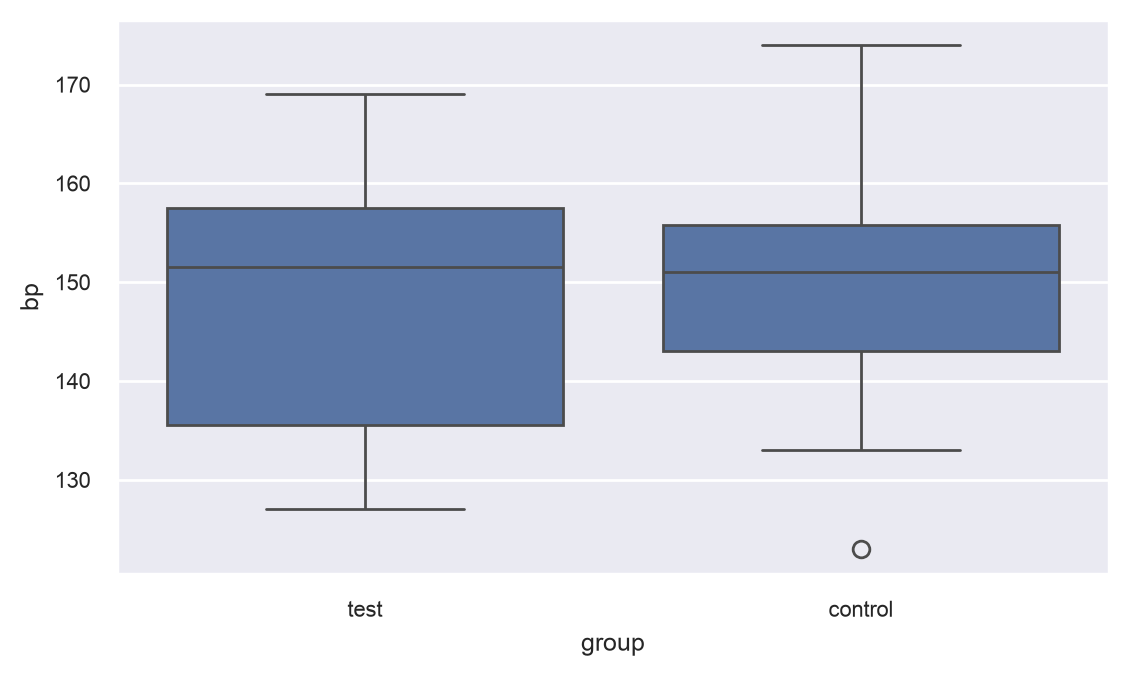

In [1194]:
sns.boxplot(data=df_bp1, x="group", y="bp");

In [1195]:
q = df_bp1.groupby("group")["bp"].quantile([0.25, 0.5, 0.75]).unstack()
overlap = q.loc["test", 0.25] < q.loc["control", 0.75] and q.loc["control", 0.25] < q.loc["test", 0.75]
print(f"The median blood pressure is {q.loc['test', 0.5]:.1f} mmHg in the test group and {q.loc['control', 0.5]:.1f} mmHg in the control group. "
      + ("The boxes overlap, so any difference is small compared with the spread within each group; a test is needed to judge it." if overlap else "The boxes do not overlap, which suggests a clear difference between the groups."))

The median blood pressure is 151.5 mmHg in the test group and 151.0 mmHg in the control group. The boxes overlap, so any difference is small compared with the spread within each group; a test is needed to judge it.


*See also:* Drawing a histogram with `histplot` (C3) · Drawing a box plot with `boxplot` (C3) · Independent (Welch) t-tests (D4) · Testing for equal variances (D4)

#### QQ plots

**D4.13**

`stats.probplot(data, dist="norm", plot=plt)`

The `stats.probplot()` function allows us to compare the data's quantiles with those of a normal distribution. It is useful for checking the normality assumption: points on the line mean approximately normal. Alternatively, `stats.shapiro` gives a single p-value for normality.

**Context.** The data are from two blood-pressure experiments (in mmHg). In experiment 1, one group received a treatment (test) and one did not (control); each person was measured once. In experiment 2, the same people were measured on day 1 and on day 30.

Points close to the line suggest that the data are approximately normal:

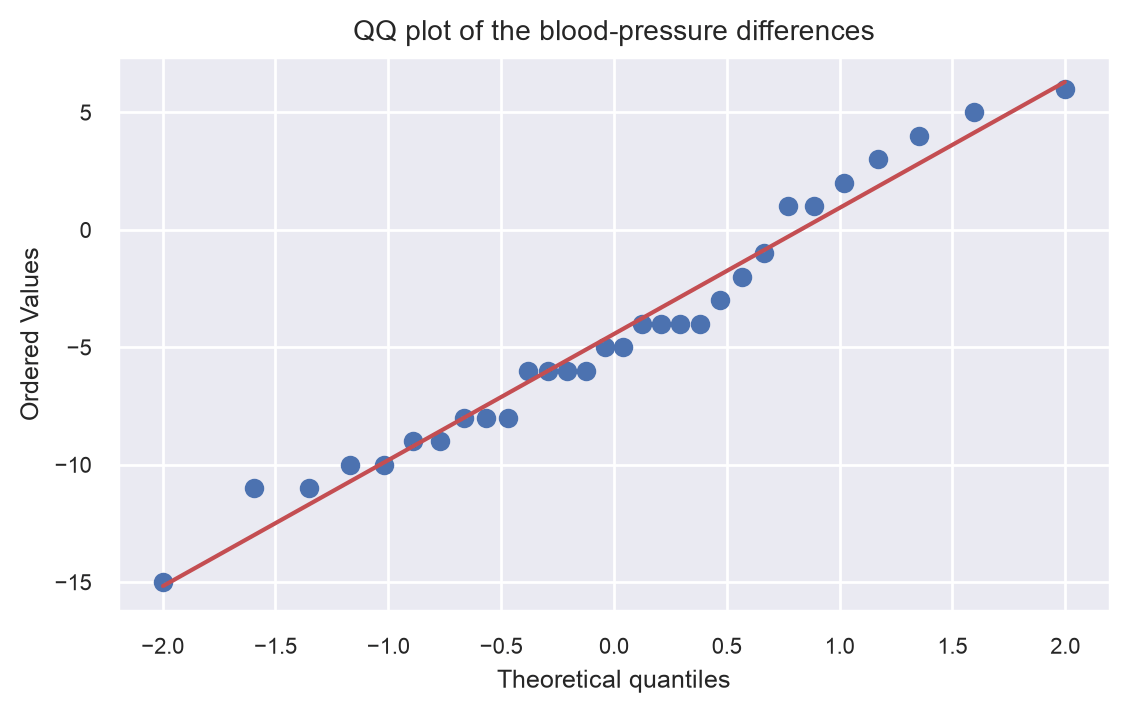

In [1196]:
stats.probplot(col_diffs, dist="norm", plot=plt)
plt.title("QQ plot of the blood-pressure differences");

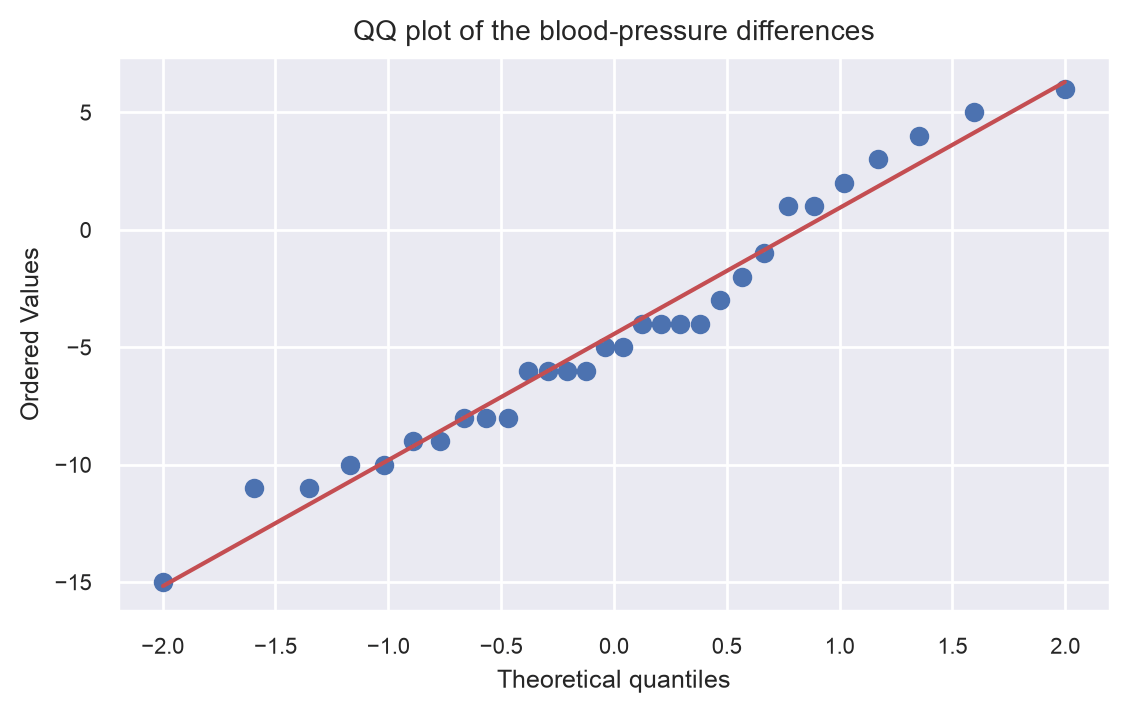

In [1197]:
# the same plot in object-oriented style (ax. methods)
fig, ax = plt.subplots()
stats.probplot(col_diffs, dist="norm", plot=ax)
ax.set_title("QQ plot of the blood-pressure differences");

*See also:* QQ plots of residuals (D5)

#### Testing for normality

**D4.14**

`stats.shapiro(x)`

***(non-examinable)***

The `stats.shapiro()` function allows us to test the null hypothesis that data are normally distributed. It is useful as a formal backup to the QQ plot. Alternatively, trust the QQ plot, especially for large samples, where the test flags trivial departures.

**Context.** The data are from two blood-pressure experiments (in mmHg). In experiment 1, one group received a treatment (test) and one did not (control); each person was measured once. In experiment 2, the same people were measured on day 1 and on day 30.

A small p-value suggests the data are *not* normal.

In [1198]:
res_sw = stats.shapiro(col_diffs)
print(f"W = {res_sw.statistic:.3f}, p = {res_sw.pvalue:.4f}")

W = 0.969, p = 0.5050


*See also:* QQ plots (D4) · Testing the residuals for normality (D5) · Testing for equal variances (D4)

#### Testing for equal variances

**D4.15**

`stats.levene(a, b)`

***(non-examinable)***

The `stats.levene()` function allows us to test whether two groups have equal variances. It is useful for deciding between Student's and Welch's test. Alternatively, use Welch's test, which does not need the assumption.

**Context.** The data are from two blood-pressure experiments (in mmHg). In experiment 1, one group received a treatment (test) and one did not (control); each person was measured once. In experiment 2, the same people were measured on day 1 and on day 30.

In [1199]:
print(f"sd test = {col_test.std():.1f} mmHg, sd control = {col_control.std():.1f} mmHg")

sd test = 11.3 mmHg, sd control = 11.7 mmHg


In [1200]:
res_lev = stats.levene(col_test, col_control)
print(f"W = {res_lev.statistic:.3f}, p = {res_lev.pvalue:.4f}")

W = 0.008, p = 0.9295


*See also:* Student or Welch (D4) · Comparing groups with a box plot (D4) · Non-parametric tests (D4)

### Write-up

#### Reporting a t-test

**D4.16**

`t(df) = , p = , mean difference (95% CI)`

***(non-examinable)***

A fixed sentence pattern allows us to report a test clearly: `t(df) = …, p = …, mean difference (95% CI …)`. It is useful because it gives the test, the evidence and the effect size in one line. Alternatively, a table works for many tests.

**Context.** The data are from two blood-pressure experiments (in mmHg). In experiment 1, one group received a treatment (test) and one did not (control); each person was measured once. In experiment 2, the same people were measured on day 1 and on day 30.

A p-value below 0.001 is reported as "p < 0.001", otherwise to 2 significant figures:

In [1201]:
r = stats.ttest_rel(df_bp2["bp_day30"], df_bp2["bp_day1"])
ci = r.confidence_interval()
p_text = "p < 0.001" if r.pvalue < 0.001 else f"p = {r.pvalue:.2g}"
print(f"t({r.df:.0f}) = {r.statistic:.2f}, {p_text}, "
      f"mean change = {col_diffs.mean():.1f} mmHg (95% CI {ci.low:.1f} to {ci.high:.1f})")

t(29) = -4.64, p < 0.001, mean change = -4.4 mmHg (95% CI -6.4 to -2.5)


*See also:* Reading the t-test output (D4) · Confidence intervals (D4) · Building text with an f-string (A1) · Reporting the size of an effect, not only p (D6) · Reporting a p-value (D6)

### Beyond the course (extensions)

#### Non-parametric tests

**D4.17**

`stats.mannwhitneyu(a, b), stats.wilcoxon(d)`

***(non-examinable)***

The `stats.mannwhitneyu()` and `stats.wilcoxon()` functions allow us to compare groups using ranks rather than means. They are useful when data are clearly not normal. Alternatively, transform the data (for example with logs) and use a t-test.

**Context.** The data are from two blood-pressure experiments (in mmHg). In experiment 1, one group received a treatment (test) and one did not (control); each person was measured once. In experiment 2, the same people were measured on day 1 and on day 30.

In [1202]:
res_mw = stats.mannwhitneyu(col_test, col_control)
res_wx = stats.wilcoxon(col_diffs)
print(f"independent groups (Mann-Whitney U): p = {res_mw.pvalue:.4f}")

independent groups (Mann-Whitney U): p = 0.5101


In [1203]:
print(f"paired differences (Wilcoxon)      : p = {res_wx.pvalue:.4f}")

paired differences (Wilcoxon)      : p = 0.0003


*See also:* Independent (Welch) t-tests (D4) · Paired t-tests (D4) · Testing for normality (D4)

#### Cohen's d

**D4.18**

`d = (m1 - m2) / pooled_sd`

***(non-examinable)***

Dividing the difference in means by the pooled standard deviation allows us to measure effect size independent of sample size. It is useful because a very small difference can be "significant" in a big sample. Alternatively, report the raw difference with its confidence interval.

**Context.** The data are from two blood-pressure experiments (in mmHg). In experiment 1, one group received a treatment (test) and one did not (control); each person was measured once. In experiment 2, the same people were measured on day 1 and on day 30.

In [1204]:
n1, n2 = len(col_test), len(col_control)
sp = np.sqrt(((n1 - 1) * col_test.var() + (n2 - 1) * col_control.var()) / (n1 + n2 - 2))
cohen_d = (col_test.mean() - col_control.mean()) / sp
print(f"pooled sd = {sp:.2f} mmHg")

pooled sd = 11.53 mmHg


In [1205]:
print(f"Cohen's d = {cohen_d:.2f}")

Cohen's d = -0.23


In [1206]:
size = "small" if abs(cohen_d) < 0.5 else "medium" if abs(cohen_d) < 0.8 else "large"
print(f"The means differ by {abs(cohen_d):.2f} pooled standard deviations, which is a {size} effect (by the usual guide of 0.2 small, 0.5 medium, 0.8 large).")

The means differ by 0.23 pooled standard deviations, which is a small effect (by the usual guide of 0.2 small, 0.5 medium, 0.8 large).


*See also:* Confidence intervals (D4) · Non-parametric tests (D4) · Reporting a t-test (D4)

#### Power analysis

**D4.19**

`TTestIndPower().solve_power(...)`

***(non-examinable)***

The `TTestIndPower` class allows us to find how many subjects per group are needed to detect an effect of a given size. It is useful when planning an experiment. Alternatively, simulate experiments with `np.random.normal`.

**Context.** The data are from two blood-pressure experiments (in mmHg). In experiment 1, one group received a treatment (test) and one did not (control); each person was measured once. In experiment 2, the same people were measured on day 1 and on day 30.

In [1207]:
from statsmodels.stats.power import TTestIndPower

In [1208]:
n = TTestIndPower().solve_power(effect_size=0.5, alpha=0.05, power=0.8)
print(f"subjects per group for a medium effect (d = 0.5): {n:.0f}")

subjects per group for a medium effect (d = 0.5): 64


In [1209]:
print(f"To detect a medium effect (d = 0.5) with 80% power at the 5% level, about {n:.0f} subjects are needed in each group.")

To detect a medium effect (d = 0.5) with 80% power at the 5% level, about 64 subjects are needed in each group.


*See also:* Drawing normal random numbers (A4) · Cohen's d (D4) · Missed effects (power) (D3)

#### Comparing more than two groups

**D4.20**

`stats.f_oneway(a, b, c)`

***(non-examinable)***

The `stats.f_oneway()` function (ANOVA) allows us to test whether any of three or more group means differ. It is useful instead of many t-tests, which inflate the false-positive rate. Alternatively, `stats.kruskal` is the non-parametric version.

**Context.** The data are the body masses (g) of penguins of the three species in the dataset.

In [1210]:
groups = [df_penguins.loc[df_penguins["species"] == s, "body_mass_g"].dropna() for s in df_penguins["species"].unique()]
print(f"penguins per species: {[len(g) for g in groups]}")

penguins per species: [151, 68, 123]


In [1211]:
res_f = stats.f_oneway(*groups)
print(f"F = {res_f.statistic:.1f}, p = {res_f.pvalue:.3g}")

F = 343.6, p = 2.89e-82


In [1212]:
f'The species differ in mean body mass (F = {res_f.statistic:.1f}, p = {res_f.pvalue:.3g}), ' + ('which is below 0.05: at least one species mean differs from the others.' if res_f.pvalue < 0.05 else 'which is not below 0.05: no evidence at the 5% level that the species differ.')

'The species differ in mean body mass (F = 343.6, p = 2.89e-82), which is below 0.05: at least one species mean differs from the others.'

*See also:* Adjusting p-values for many tests (D4) · Drawing a box plot with `boxplot` (C3) · Comparing groups with a box plot (D4)

#### Adjusting p-values for many tests

**D4.21**

`multipletests(pvals, method="holm")`

***(non-examinable)***

The `multipletests()` function allows us to adjust p-values when several tests are run. It is useful because the more tests are run, the more likely one is "significant" by chance. Alternatively, apply a Bonferroni correction by multiplying p-values by the number of tests.

**Context.** The data are from two blood-pressure experiments (in mmHg). In experiment 1, one group received a treatment (test) and one did not (control); each person was measured once. In experiment 2, the same people were measured on day 1 and on day 30.

In [1213]:
from statsmodels.stats.multitest import multipletests

In [1214]:
raw = [0.01, 0.04, 0.03]
reject, adjusted, *_ = multipletests(raw, method="holm")
print(f"raw      : {raw}")

raw      : [0.01, 0.04, 0.03]


In [1215]:
print(f"adjusted : {adjusted.round(3).tolist()}")

adjusted : [0.03, 0.06, 0.06]


*See also:* Comparing more than two groups (D4) · Non-parametric tests (D4) · Independent (Welch) t-tests (D4)